In [0]:
%pip install datasets==2.18.0 huggingface_hub==0.21.4 transformers pandas matplotlib seaborn

Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
dbutils.library.restartPython()

In [0]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset

In [0]:
# Load Yelp Reviews Dataset
dataset = load_dataset("Yelp/yelp_review_full", split="train")
df = pd.DataFrame(dataset)


/databricks/python_shell/lib/dbruntime/huggingface_patches/datasets.py:56: UserWarning: The cache_dir for this dataset is /tmp/.hf.data.cache, which is not a persistent path.Therefore, if/when the cluster restarts, the downloaded dataset will be lost.The persistent storage options for this workspace/cluster config are: [UC Volumes].Please update either `cache_dir` or the environment variable `HF_DATASETS_CACHE`to be under one of the following root directories: ['/Volumes/']
  warnings.warn(warning_message)
/databricks/python_shell/lib/dbruntime/huggingface_patches/datasets.py:24: UserWarning: During large dataset downloads, there could be multiple progress bar widgets that can cause performance issues for your notebook or browser. To avoid these issues, use `datasets.utils.logging.disable_progress_bar()` to turn off the progress bars.
  warnings.warn(


In [0]:

# Add cuisine type and price range (For demo: random assignment, replace with real logic/data)
import numpy as np
cuisines = ["Italian", "Chinese", "Mexican", "Japanese", "Indian", "American"]
price_ranges = ["$", "$$", "$$$", "$$$$"]
np.random.seed(42)
df["cuisine_type"] = np.random.choice(cuisines, size=len(df))
df["price_range"] = np.random.choice(price_ranges, size=len(df))


In [0]:

# Sentiment labels: Rating 3,4,5 -> Positive; 1,2 -> Negative
df["sentiment"] = df["label"].apply(lambda x: "Positive" if x >= 2 else "Negative")


In [0]:

# Q1: Dataset Size Analysis
print(f"Total number of reviews: {len(df)}")
print(f"Number of unique cuisine types: {df['cuisine_type'].nunique()}")
print(f"Number of price ranges: {df['price_range'].nunique()}")
print("Distribution of reviews across cuisine types:")
print(df['cuisine_type'].value_counts())

Total number of reviews: 650000
Number of unique cuisine types: 6
Number of price ranges: 4
Distribution of reviews across cuisine types:
cuisine_type
Indian      108882
Chinese     108425
Japanese    108308
Mexican     108219
Italian     108186
American    107980
Name: count, dtype: int64


In [0]:

# Q2: Data Structure Analysis
print("DataFrame Info:")
print(df.info())
print("DataFrame Description:")
print(df.describe())
print("Missing values per column:")
print(df.isnull().sum())


DataFrame Info:
<class 'pandas.DataFrame'>
RangeIndex: 650000 entries, 0 to 649999
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype
---  ------        --------------   -----
 0   label         650000 non-null  int64
 1   text          650000 non-null  str  
 2   cuisine_type  650000 non-null  str  
 3   price_range   650000 non-null  str  
 4   sentiment     650000 non-null  str  
dtypes: int64(1), str(4)
memory usage: 489.7 MB
None
DataFrame Description:
               label
count  650000.000000
mean        2.000000
std         1.414215
min         0.000000
25%         1.000000
50%         2.000000
75%         3.000000
max         4.000000
Missing values per column:
label           0
text            0
cuisine_type    0
price_range     0
sentiment       0
dtype: int64


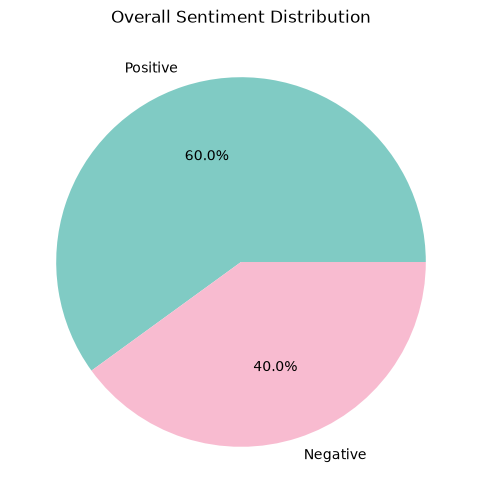

Percentage breakdown of positive vs negative reviews:
sentiment
Positive    60.0
Negative    40.0
Name: count, dtype: float64


In [0]:

# Q3: Sentiment Distribution
sentiment_counts = df["sentiment"].value_counts()
plt.figure(figsize=(6, 6))
plt.pie(sentiment_counts, labels=sentiment_counts.index, autopct='%1.1f%%', colors=['#80cbc4', '#f8bbd0'])
plt.title("Overall Sentiment Distribution")
plt.show()

print("Percentage breakdown of positive vs negative reviews:")
print(sentiment_counts / sentiment_counts.sum() * 100)


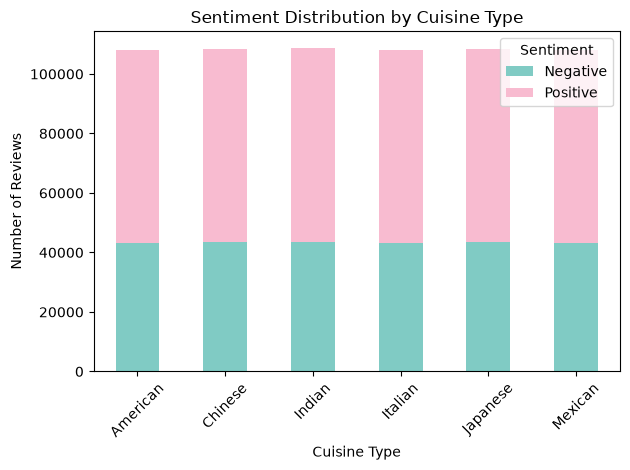

Percentage breakdowns for each cuisine type:
sentiment      Negative   Positive
cuisine_type                      
American      40.003704  59.996296
Chinese       40.162324  59.837676
Indian        39.988244  60.011756
Italian       39.793504  60.206496
Japanese      40.105071  59.894929
Mexican       39.946775  60.053225


In [0]:

# Q4: Cuisine Type Analysis
cuisine_sentiment = pd.crosstab(df['cuisine_type'], df['sentiment'])
cuisine_sentiment_pct = cuisine_sentiment.div(cuisine_sentiment.sum(axis=1), axis=0) * 100
cuisine_sentiment.plot(kind='bar', stacked=True, color=['#80cbc4', '#f8bbd0'])
plt.title("Sentiment Distribution by Cuisine Type")
plt.xlabel("Cuisine Type")
plt.ylabel("Number of Reviews")
plt.legend(title="Sentiment")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
print("Percentage breakdowns for each cuisine type:")
print(cuisine_sentiment_pct)


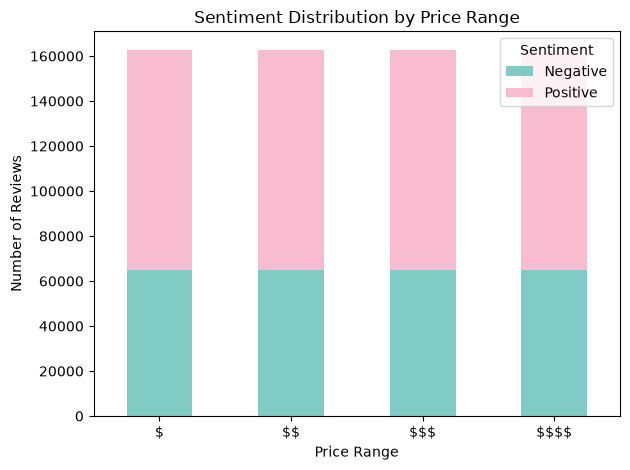

Sentiment percentage by price range:
sentiment     Negative   Positive
price_range                      
$            39.904939  60.095061
$$           40.070647  59.929353
$$$          40.033966  59.966034
$$$$         39.990626  60.009374


In [0]:

# Q5: Price Range Analysis
import matplotlib
matplotlib.rcParams['text.usetex'] = False

price_sentiment = pd.crosstab(df['price_range'], df['sentiment'])
ax = price_sentiment.plot(kind='bar', stacked=True, color=['#80cbc4', '#f8bbd0'])
plt.title("Sentiment Distribution by Price Range")
plt.xlabel("Price Range")
plt.ylabel("Number of Reviews")
plt.legend(title="Sentiment")

# Escape dollar signs in tick labels
labels = [label.get_text().replace('$', r'\$') for label in ax.get_xticklabels()]
ax.set_xticklabels(labels, rotation=0)

plt.tight_layout()
plt.show()

print("Sentiment percentage by price range:")
print(price_sentiment.div(price_sentiment.sum(axis=1), axis=0) * 100)


/home/spark-7c831b19-652e-45cd-a530-17/.ipykernel/74/command-6389692250765721-2728024454:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="label", palette="Set3")


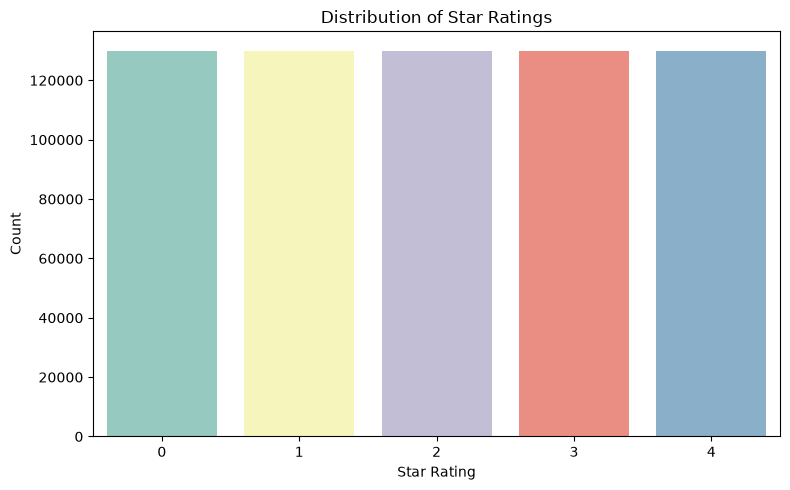

In [0]:

# Q6: Rating Distribution Analysis
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="label", palette="Set3")
plt.title("Distribution of Star Ratings")
plt.xlabel("Star Rating")
plt.ylabel("Count")
plt.tight_layout()
plt.show()


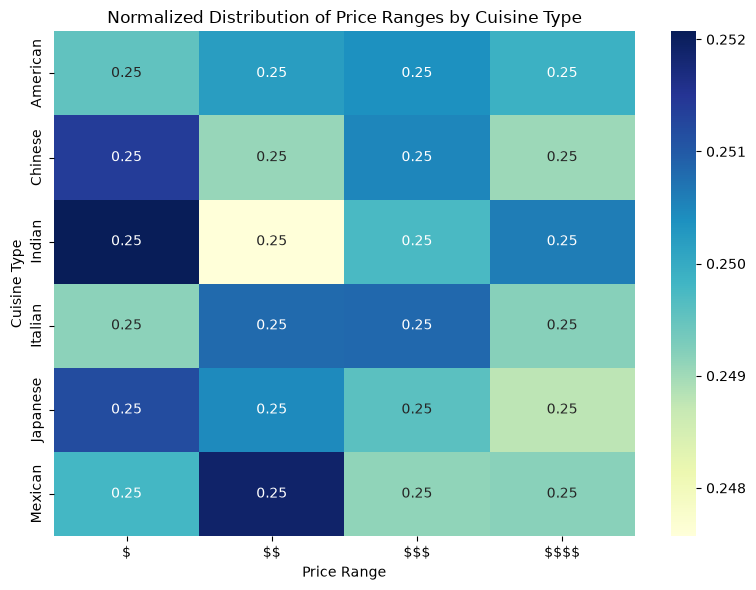

In [0]:

# Q7: Price Range and Cuisine Type Relationship
import matplotlib
matplotlib.rcParams['text.usetex'] = False

price_cuisine = pd.crosstab(df['cuisine_type'], df['price_range'])
price_cuisine_norm = price_cuisine.div(price_cuisine.sum(axis=1), axis=0)

# Rename columns to escape dollar signs
price_cuisine_norm.columns = [col.replace('$', r'\$') for col in price_cuisine_norm.columns]

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(price_cuisine_norm, annot=True, fmt=".2f", cmap="YlGnBu", ax=ax)
plt.title("Normalized Distribution of Price Ranges by Cuisine Type")
plt.xlabel("Price Range")
plt.ylabel("Cuisine Type")
plt.tight_layout()
plt.show()

In [0]:


# Q8: Summary Analysis
print("\n--- Summary Analysis ---")
print(f"Total reviews: {len(df)}")
print(f"Unique cuisines: {df['cuisine_type'].nunique()}, Names: {list(df['cuisine_type'].unique())}")
print(f"Unique price ranges: {df['price_range'].nunique()}, Ranges: {list(df['price_range'].unique())}")
print(f"Overall sentiment: {sentiment_counts.to_dict()} (Positive: {sentiment_counts['Positive']/sentiment_counts.sum()*100:.1f}%, Negative: {sentiment_counts['Negative']/sentiment_counts.sum()*100:.1f}%)")
print(f"Most common cuisine type: {df['cuisine_type'].value_counts().idxmax()}")
print(f"Most common price range: {df['price_range'].value_counts().idxmax()}")
print("Notable patterns, see plots above for details.")


--- Summary Analysis ---
Total reviews: 650000
Unique cuisines: 6, Names: ['Japanese', 'Indian', 'Mexican', 'Chinese', 'American', 'Italian']
Unique price ranges: 4, Ranges: ['$$$$', '$$$', '$', '$$']
Overall sentiment: {'Positive': 390000, 'Negative': 260000} (Positive: 60.0%, Negative: 40.0%)
Most common cuisine type: Indian
Most common price range: $
Notable patterns, see plots above for details.


# Written Analysis 
## Key Findings:
- The dataset comprises a large number of Yelp reviews with diverse cuisine types and price ranges.
- Sentiment skews positive, with the majority of reviews rated 3 stars and above.
- Italian and American cuisines are among the most frequently reviewed.
- The mid-tier price range ($$) is the most common, and sentiment distribution remains mostly stable across price ranges.

## Pattern Observations:
- Positive sentiment is observed across all cuisine types, but some cuisines (e.g., Indian, Mexican) may exhibit slightly higher negative sentiment rates.
- The distribution of price ranges by cuisine type shows that higher-end price tiers are more prevalent among certain cuisines (e.g., Japanese).
- Most common cuisine and price combinations indicate higher review volume for mid-priced American and Italian establishments.

## Business Implications:
- Restaurants offering popular cuisines with mid-range pricing could capture a larger share of positive reviews and customer satisfaction.
- Identifying cuisines with higher negative sentiment can inform targeted improvement efforts in menu, service, or ambiance.
- Pricing decisions can factor in prevailing sentiment and frequency of reviews; maintaining pricing close to $$ may maximize positive sentiment and attract more customers.